# Decision tree / random forest regression: predicting SBP/DBP from PPG morphology features

Uses all 4 features: amplitude, heart rate, pulse width, augmentation index.

Two changes from the earlier version:
- **Random forest instead of a single decision tree** -- averages over many trees instead of
  relying on one, which should reduce the high-variance, "flat band" predictions the single tree made.
- **Patient-level train/test split** -- `feature_extraction.ipynb` now tracks which original record
  each window came from (`record_ids`). The split below puts a whole patient's windows entirely in
  train or entirely in test, so the model can't partly "recognize" a patient it saw during training.
  It's also stratified by each patient's median SBP, so both the train and test sets cover the full
  range of blood pressures rather than, say, test ending up with only high-BP patients by chance.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

data = np.load("data/features_dataset.npz", allow_pickle=True)
feature_names = list(data["feature_names"])
X_all = data["X"]
y = data["y"]  # (N, 2): [SBP, DBP]
record_ids = data["record_ids"]

selected_features = ["amplitude", "heart_rate", "pulse_width", "augmentation_index"]
feature_idx = [feature_names.index(name) for name in selected_features]
X = X_all[:, feature_idx]

print(f"{len(X)} windows from {len(np.unique(record_ids))} patients")


493573 windows from 11585 patients


## Patient-level, BP-stratified split

Each patient gets a median SBP, binned into 5 quantile buckets. Patients (not windows) are then
split train/test stratified on that bucket, so the distribution of blood pressures looks similar
on both sides.

In [2]:
df = pd.DataFrame({"record_id": record_ids, "sbp": y[:, 0]})
patient_median_sbp = df.groupby("record_id")["sbp"].median()
unique_records = patient_median_sbp.index.values
sbp_bins = pd.qcut(patient_median_sbp.values, q=5, labels=False, duplicates="drop")

train_records, test_records = train_test_split(
    unique_records, test_size=0.2, stratify=sbp_bins, random_state=42
)

train_mask = np.isin(record_ids, train_records)
test_mask = np.isin(record_ids, test_records)

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"train: {len(X_train)} windows from {len(train_records)} patients")
print(f"test:  {len(X_test)} windows from {len(test_records)} patients")


train: 391283 windows from 9268 patients
test:  102290 windows from 2317 patients


SBP range -- train: [80, 180] mean=127.6  |  test: [80, 180] mean=127.9
DBP range -- train: [50, 110] mean=67.4  |  test: [50, 110] mean=67.0


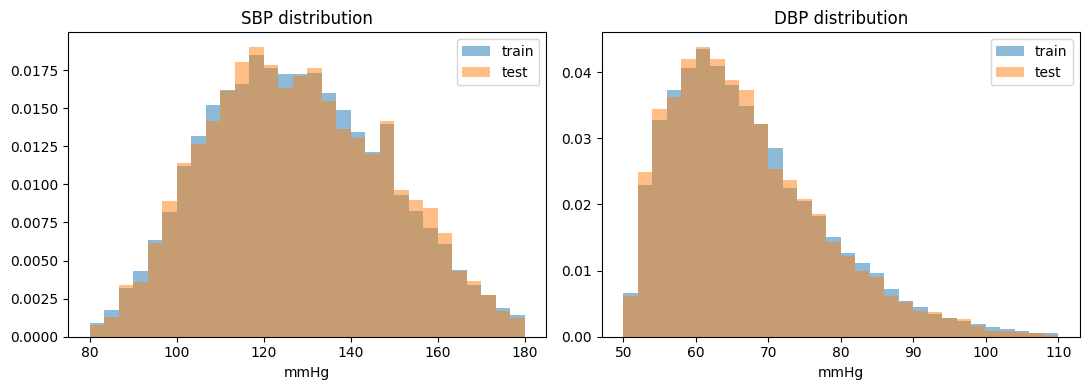

In [3]:
for i, name in enumerate(["SBP", "DBP"]):
    print(f"{name} range -- train: [{y_train[:,i].min():.0f}, {y_train[:,i].max():.0f}] "
          f"mean={y_train[:,i].mean():.1f}  |  "
          f"test: [{y_test[:,i].min():.0f}, {y_test[:,i].max():.0f}] mean={y_test[:,i].mean():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, name in enumerate(["SBP", "DBP"]):
    ax[i].hist(y_train[:, i], bins=30, alpha=0.5, density=True, label="train")
    ax[i].hist(y_test[:, i], bins=30, alpha=0.5, density=True, label="test")
    ax[i].set_title(f"{name} distribution")
    ax[i].set_xlabel("mmHg")
    ax[i].legend()
plt.tight_layout()
plt.show()


In [4]:
forest = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)

train_pred = forest.predict(X_train)
test_pred = forest.predict(X_test)


In [5]:
target_names = ["SBP", "DBP"]

for i, name in enumerate(target_names):
    train_mae = mean_absolute_error(y_train[:, i], train_pred[:, i])
    test_mae = mean_absolute_error(y_test[:, i], test_pred[:, i])
    train_rmse = np.sqrt(mean_squared_error(y_train[:, i], train_pred[:, i]))
    test_rmse = np.sqrt(mean_squared_error(y_test[:, i], test_pred[:, i]))
    train_r2 = r2_score(y_train[:, i], train_pred[:, i])
    test_r2 = r2_score(y_test[:, i], test_pred[:, i])
    print(f"{name}: train MAE={train_mae:.2f} RMSE={train_rmse:.2f} R2={train_r2:.3f} | "
          f"test MAE={test_mae:.2f} RMSE={test_rmse:.2f} R2={test_r2:.3f}")

print()
print("Feature importances:")
for name, imp in zip(selected_features, forest.feature_importances_):
    print(f"  {name}: {imp:.3f}")


SBP: train MAE=13.87 RMSE=17.57 R2=0.251 | test MAE=14.90 RMSE=18.72 R2=0.151
DBP: train MAE=7.43 RMSE=9.65 R2=0.191 | test MAE=7.72 RMSE=9.88 R2=0.104

Feature importances:
  amplitude: 0.200
  heart_rate: 0.349
  pulse_width: 0.273
  augmentation_index: 0.179


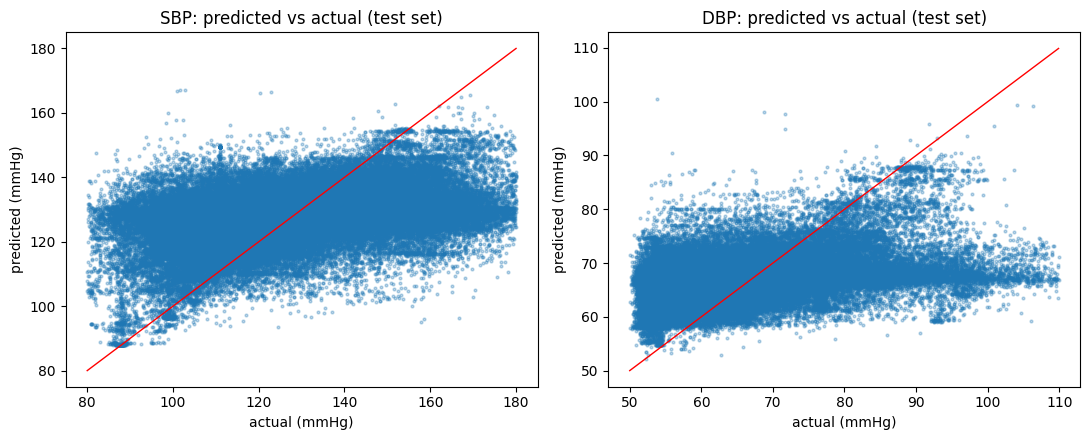

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for i, name in enumerate(target_names):
    ax[i].scatter(y_test[:, i], test_pred[:, i], s=4, alpha=0.3)
    lims = [y_test[:, i].min(), y_test[:, i].max()]
    ax[i].plot(lims, lims, color="red", linewidth=1)
    ax[i].set_title(f"{name}: predicted vs actual (test set)")
    ax[i].set_xlabel("actual (mmHg)")
    ax[i].set_ylabel("predicted (mmHg)")
plt.tight_layout()
plt.show()
